# Late Night Phone Habits Analysis and Fatigue Prediction
## Deliverable 1 – Data Analysis Report

---
# CLO1: Introduction and Data Wrangling

### Import libraries and load the dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("samartalwar/sleep-debt-and-screen-time-late-night-phone-habits")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Zain Faisal\.cache\kagglehub\datasets\samartalwar\sleep-debt-and-screen-time-late-night-phone-habits\versions\1


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv(os.path.join(path, 'bedtime_screentime_sleep_debt.csv'))

print("Dataset shape (rows, columns):", df.shape)
df.head()

Dataset shape (rows, columns): (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


### Structure of the dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [4]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Missing values per column:
user_id                     0
age                         0
gender                      0
occupation_type             0
chronotype                  0
bedtime_phone_minutes       0
primary_bedtime_app         0
screen_brightness_pct       0
blue_light_filter_active    0
caffeine_post_5pm_mg        0
physical_activity_min       0
sleep_latency_min           0
total_sleep_hours           0
deep_sleep_pct              0
rem_sleep_pct               0
morning_alarm_snoozes       0
next_day_fatigue_score      0
sleep_debt_category         0
dtype: int64

Duplicate records: 0


### Numerical and categorical variables

In [5]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
categorical_cols.remove("user_id")               # identifier only, not used in analysis

print("Numerical variables  :", numerical_cols)
print("Categorical variables:", categorical_cols)

Numerical variables  : ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']
Categorical variables: ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app', 'sleep_debt_category']


### Identify dependent and independent variables

In [6]:
dependent_var = "next_day_fatigue_score"
independent_vars = [c for c in df.columns if c not in ["user_id", dependent_var]]

X = df[independent_vars]
y = df[dependent_var]

print("Dependent variable (y):", dependent_var)
print("Independent variables (X):", independent_vars)
print("Number of independent variables:", len(independent_vars))
print("X shape:", X.shape, "| y shape:", y.shape)

# Main independent variable (used for scatter plot, correlation and simple regression)
main_independent = "bedtime_phone_minutes"
print("\nMain independent variable:", main_independent)

Dependent variable (y): next_day_fatigue_score
Independent variables (X): ['age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'sleep_debt_category']
Number of independent variables: 16
X shape: (8500, 16) | y shape: (8500,)

Main independent variable: bedtime_phone_minutes


### Sampling decision

In [7]:
population_size = len(df)
sample_size = 150

print("Population size:", population_size)
print("Sample size    :", sample_size)

Population size: 8500
Sample size    : 150


---
# CLO2: Descriptive, Exploratory and Statistical Analysis

### Script for Descriptive Analysis
Function takes the **sample** and the **field** as input and returns its descriptive statistics.

In [8]:
def descriptive_stats(sample, field):
    data = sample[field]
    stats_dict = {
        "Count": data.count(),
        "Mean": data.mean(),
        "Median": data.median(),
        "Mode": data.mode()[0],
        "Standard Deviation": data.std(),
        "Variance": data.var(),
        "Minimum": data.min(),
        "Maximum": data.max(),
        "Range": data.max() - data.min(),
        "Q1 (25%)": data.quantile(0.25),
        "Q3 (75%)": data.quantile(0.75),
        "IQR": data.quantile(0.75) - data.quantile(0.25),
        "Skewness": data.skew(),
        "Kurtosis": data.kurt()
    }
    return pd.Series(stats_dict, name=field).round(3)

### Random Sampling (n = 150)

In [9]:
random_sample = df.sample(n=150, random_state=42)

print("Random sample size:", len(random_sample))
print("\nDescriptive statistics of", dependent_var, "(Random Sample):")
print(descriptive_stats(random_sample, dependent_var))

Random sample size: 150

Descriptive statistics of next_day_fatigue_score (Random Sample):
Count                 150.000
Mean                    3.648
Median                  3.150
Mode                    1.000
Standard Deviation      2.595
Variance                6.734
Minimum                 1.000
Maximum                10.000
Range                   9.000
Q1 (25%)                1.000
Q3 (75%)                5.200
IQR                     4.200
Skewness                0.759
Kurtosis               -0.406
Name: next_day_fatigue_score, dtype: float64


### Systematic Sampling (with condition)
Condition: users who used their phone for **30 minutes or more** before bed. From these users every k-th record is selected to get 150 records.

In [10]:
condition_df = df[df["bedtime_phone_minutes"] >= 30].reset_index(drop=True)

n = 150
k = max(len(condition_df) // n, 1)      # sampling interval
start = 0                                # starting point

systematic_sample = condition_df.iloc[start::k].head(n)

print("Records meeting the condition:", len(condition_df))
print("Sampling interval (k):", k)
print("Systematic sample size:", len(systematic_sample))
print("\nDescriptive statistics of", dependent_var, "(Systematic Sample):")
print(descriptive_stats(systematic_sample, dependent_var))

Records meeting the condition: 6573
Sampling interval (k): 43
Systematic sample size: 150

Descriptive statistics of next_day_fatigue_score (Systematic Sample):
Count                 150.000
Mean                    4.611
Median                  4.300
Mode                    1.000
Standard Deviation      2.605
Variance                6.785
Minimum                 1.000
Maximum                10.000
Range                   9.000
Q1 (25%)                2.425
Q3 (75%)                6.475
IQR                     4.050
Skewness                0.398
Kurtosis               -0.785
Name: next_day_fatigue_score, dtype: float64


### Descriptive Statistical Report (Dependent Variable – full dataset)

In [11]:
print("Descriptive statistics of", dependent_var, "(Full Dataset):")
print(descriptive_stats(df, dependent_var))

Descriptive statistics of next_day_fatigue_score (Full Dataset):
Count                 8500.000
Mean                     3.795
Median                   3.200
Mode                     1.000
Standard Deviation       2.685
Variance                 7.210
Minimum                  1.000
Maximum                 10.000
Range                    9.000
Q1 (25%)                 1.100
Q3 (75%)                 5.600
IQR                      4.500
Skewness                 0.746
Kurtosis                -0.479
Name: next_day_fatigue_score, dtype: float64


In [12]:
# Comparison of population, random sample and systematic sample
comparison = pd.DataFrame({
    "Population": descriptive_stats(df, dependent_var),
    "Random Sample": descriptive_stats(random_sample, dependent_var),
    "Systematic Sample": descriptive_stats(systematic_sample, dependent_var)
})
comparison

,Population,Random Sample,Systematic Sample
Count,8500.000,150.000,150.000
Mean,3.795,3.648,4.611
Median,3.200,3.150,4.300
Mode,1.000,1.000,1.000
Standard Deviation,2.685,2.595,2.605
Variance,7.210,6.734,6.785
Minimum,1.000,1.000,1.000
Maximum,10.000,10.000,10.000
Range,9.000,9.000,9.000
Q1 (25%),1.100,1.000,2.425


In [13]:
# Mean fatigue score by sleep debt category
df.groupby("sleep_debt_category")[dependent_var].agg(["count", "mean", "median", "std"]).round(3)

,count,mean,median,std
sleep_debt_category,,,,
Mild Deficit,2004,1.828,1.4,1.016
Moderate Debt,4462,4.683,4.6,1.880
Optimal Recovery,1387,1.081,1.0,0.318
Severe Sleep Debt,647,9.581,9.9,0.499


### Visualisation through Various Charts

#### Scatter Plot

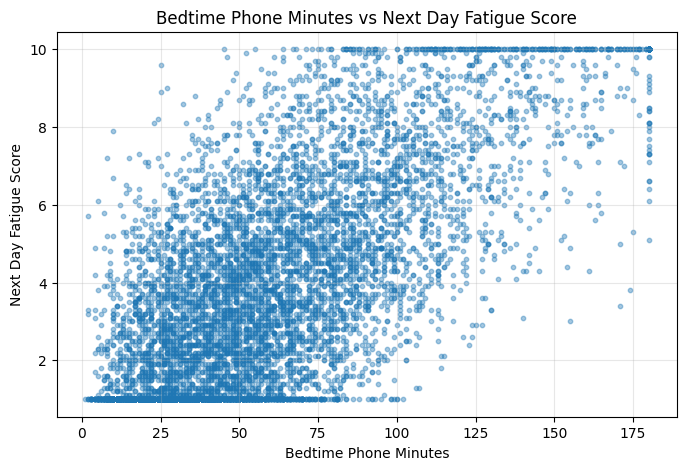

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(df[main_independent], df[dependent_var], alpha=0.4, s=10)
plt.title("Bedtime Phone Minutes vs Next Day Fatigue Score")
plt.xlabel("Bedtime Phone Minutes")
plt.ylabel("Next Day Fatigue Score")
plt.grid(alpha=0.3)
plt.show()

#### Box Plot

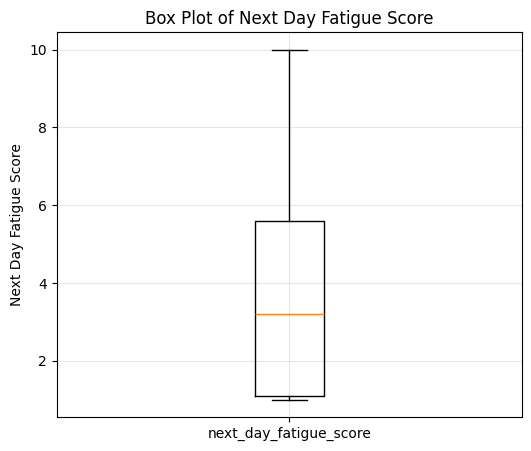

Number of outliers in next_day_fatigue_score : 0


In [15]:
plt.figure(figsize=(6, 5))
plt.boxplot(df[dependent_var])
plt.title("Box Plot of Next Day Fatigue Score")
plt.ylabel("Next Day Fatigue Score")
plt.xticks([1], ["next_day_fatigue_score"])
plt.grid(alpha=0.3)
plt.show()

# Outliers using IQR rule
Q1 = df[dependent_var].quantile(0.25)
Q3 = df[dependent_var].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df[dependent_var] < Q1 - 1.5 * IQR) | (df[dependent_var] > Q3 + 1.5 * IQR)]
print("Number of outliers in", dependent_var, ":", len(outliers))

#### Histogram

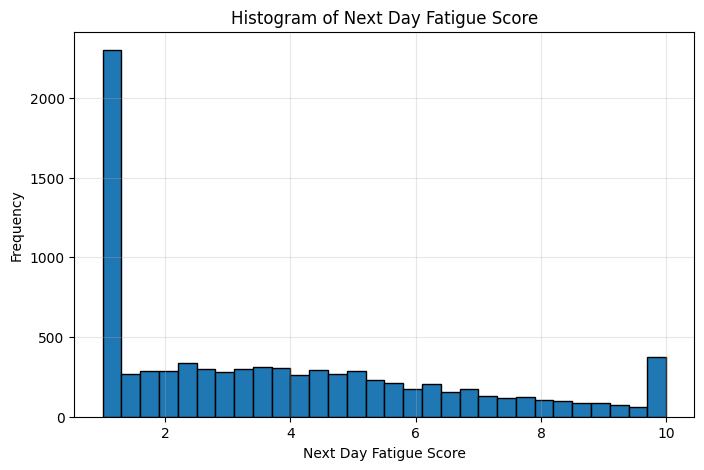

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df[dependent_var], bins=30, edgecolor="black")
plt.title("Histogram of Next Day Fatigue Score")
plt.xlabel("Next Day Fatigue Score")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

#### Heat Map

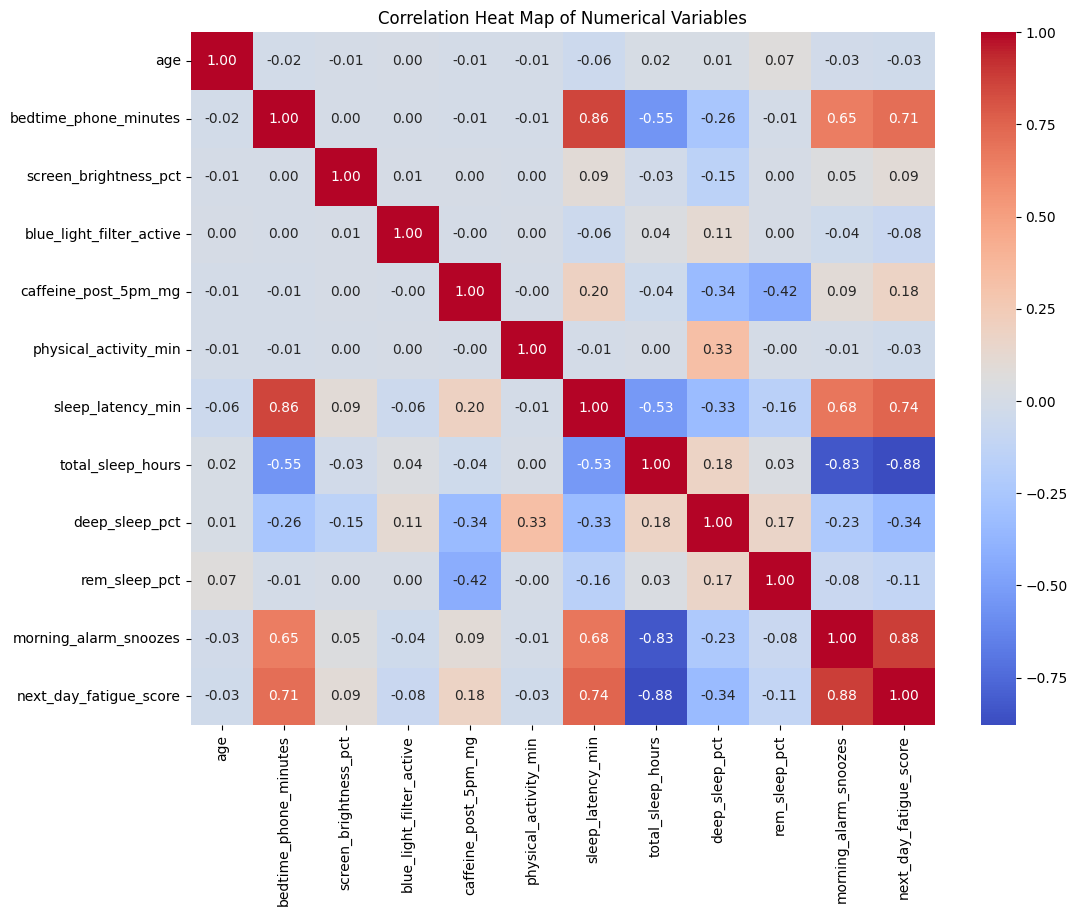

Correlation of each variable with next_day_fatigue_score :
morning_alarm_snoozes       0.881
sleep_latency_min           0.745
bedtime_phone_minutes       0.711
caffeine_post_5pm_mg        0.181
screen_brightness_pct       0.093
age                        -0.028
physical_activity_min      -0.029
blue_light_filter_active   -0.077
rem_sleep_pct              -0.115
deep_sleep_pct             -0.341
total_sleep_hours          -0.879
Name: next_day_fatigue_score, dtype: float64


In [17]:
plt.figure(figsize=(12, 9))
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heat Map of Numerical Variables")
plt.show()

print("Correlation of each variable with", dependent_var, ":")
print(corr_matrix[dependent_var].drop(dependent_var).sort_values(ascending=False).round(3))

### Hypothesis Test
**Numerical:** bedtime_phone_minutes vs next_day_fatigue_score (Pearson and Spearman)  
- H0: There is no correlation between bedtime phone minutes and next day fatigue score.  
- H1: There is a correlation between bedtime phone minutes and next day fatigue score.  

Significance level α = 0.05

In [18]:
alpha = 0.05

# Pearson correlation
pearson_r, pearson_p = stats.pearsonr(df[main_independent], df[dependent_var])
print("Pearson correlation coefficient (r):", round(pearson_r, 4))
print("Pearson p-value:", pearson_p)
if pearson_p < alpha:
    print("Result: Reject H0 - there is a significant linear correlation.")
else:
    print("Result: Fail to reject H0 - no significant linear correlation.")

# Spearman correlation
spearman_r, spearman_p = stats.spearmanr(df[main_independent], df[dependent_var])
print("\nSpearman correlation coefficient (rho):", round(spearman_r, 4))
print("Spearman p-value:", spearman_p)
if spearman_p < alpha:
    print("Result: Reject H0 - there is a significant monotonic correlation.")
else:
    print("Result: Fail to reject H0 - no significant monotonic correlation.")

Pearson correlation coefficient (r): 0.7105
Pearson p-value: 0.0
Result: Reject H0 - there is a significant linear correlation.

Spearman correlation coefficient (rho): 0.6654
Spearman p-value: 0.0
Result: Reject H0 - there is a significant monotonic correlation.


**Categorical:** sleep_debt_category vs fatigue level (Chi-Square)  
The fatigue score is grouped into three levels (Low, Medium, High) using equal-sized groups so it can be tested against a categorical variable.  
- H0: Sleep debt category and fatigue level are independent.  
- H1: Sleep debt category and fatigue level are associated.

In [19]:
df["fatigue_level"] = pd.qcut(df[dependent_var], q=3, labels=["Low", "Medium", "High"])

contingency_table = pd.crosstab(df["sleep_debt_category"], df["fatigue_level"])
print("Contingency Table:")
print(contingency_table)

chi2, chi_p, dof, expected = stats.chi2_contingency(contingency_table)
print("\nChi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("p-value:", chi_p)
if chi_p < alpha:
    print("Result: Reject H0 - sleep debt category and fatigue level are associated.")
else:
    print("Result: Fail to reject H0 - no significant association.")

Contingency Table:
fatigue_level         Low  Medium  High
sleep_debt_category                    
Mild Deficit         1240     737    27
Moderate Debt         284    2074  2104
Optimal Recovery     1334      53     0
Severe Sleep Debt       0       0   647

Chi-square statistic: 6339.4856
Degrees of freedom: 6
p-value: 0.0
Result: Reject H0 - sleep debt category and fatigue level are associated.


### One Sample T-test
Checks whether the sample mean of next_day_fatigue_score is equal to the population mean.  
- H0: Sample mean = Population mean (sample is representative).  
- H1: Sample mean ≠ Population mean (sample is not representative).  

Significance level α = 0.05

In [20]:
population_mean = df[dependent_var].mean()
print("Population mean:", round(population_mean, 4))

for name, sample in [("Random Sample", random_sample), ("Systematic Sample", systematic_sample)]:
    t_stat, t_p = stats.ttest_1samp(sample[dependent_var], population_mean)
    print("\n" + name)
    print("Sample mean:", round(sample[dependent_var].mean(), 4))
    print("t-statistic:", round(t_stat, 4))
    print("p-value:", round(t_p, 4))
    if t_p < alpha:
        print("Result: Reject H0 - the sample is NOT representative of the population.")
    else:
        print("Result: Fail to reject H0 - the sample is representative of the population.")

Population mean: 3.7947

Random Sample
Sample mean: 3.648
t-statistic: -0.6922
p-value: 0.4899
Result: Fail to reject H0 - the sample is representative of the population.

Systematic Sample
Sample mean: 4.6107
t-statistic: 3.8367
p-value: 0.0002
Result: Reject H0 - the sample is NOT representative of the population.


---
# Deliverable 2 – CLO3: Machine Learning Models (Regression, Classification and Clustering)

## 1. Data Collection
Import the machine learning libraries and separate the independent variables (X) and the dependent variable (y).

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, silhouette_score)
from scipy.cluster.hierarchy import dendrogram, linkage

# Working copy of the dataset for modelling
# (user_id is only an identifier; fatigue_level was created in D1 for the chi-square test only)
df_model = df.drop(columns=["user_id", "fatigue_level"], errors="ignore").copy()

X = df_model.drop(columns=[dependent_var])
y = df_model[dependent_var]

print("Shape of X (independent variables):", X.shape)
print("Shape of y (dependent variable):", y.shape)
print("\nIndependent variables:", X.columns.tolist())

Shape of X (independent variables): (8500, 16)
Shape of y (dependent variable): (8500,)

Independent variables: ['age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'sleep_debt_category']


## 2. Data Cleaning
Check for missing values, duplicate records and outliers in the numerical variables.

In [22]:
# Missing values
print("Total missing values:", df_model.isnull().sum().sum())

# Fill missing values if any: median for numerical, mode for categorical
for col in df_model.columns:
    if df_model[col].isnull().sum() > 0:
        if df_model[col].dtype in ["int64", "float64"]:
            df_model[col] = df_model[col].fillna(df_model[col].median())
        else:
            df_model[col] = df_model[col].fillna(df_model[col].mode()[0])

# Duplicate records
print("Duplicate records:", df_model.duplicated().sum())
df_model = df_model.drop_duplicates()

Total missing values: 0
Duplicate records: 0


In [23]:
# Outliers in numerical variables using the IQR rule
num_features = df_model.select_dtypes(include="number").columns.tolist()

outlier_summary = []
for col in num_features:
    q1 = df_model[col].quantile(0.25)
    q3 = df_model[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df_model[col] < lower) | (df_model[col] > upper)).sum()
    outlier_summary.append([col, round(lower, 2), round(upper, 2), count])

outlier_summary = pd.DataFrame(outlier_summary, columns=["Variable", "Lower Limit", "Upper Limit", "Outliers"])
outlier_summary

,Variable,Lower Limit,Upper Limit,Outliers
0,age,-0.50,67.50,0
1,bedtime_phone_minutes,-41.00,151.00,237
2,screen_brightness_pct,1.50,109.50,0
3,blue_light_filter_active,-1.50,2.50,0
4,caffeine_post_5pm_mg,-82.50,137.50,483
5,physical_activity_min,-22.50,93.50,40
6,sleep_latency_min,-4.05,81.95,247
7,total_sleep_hours,2.08,10.51,0
8,deep_sleep_pct,13.40,30.20,50
9,rem_sleep_pct,12.30,25.90,76


In [24]:
# Check that values are inside their valid ranges
print("Fatigue score range      :", df_model[dependent_var].min(), "to", df_model[dependent_var].max())
print("Screen brightness range  :", df_model["screen_brightness_pct"].min(), "to", df_model["screen_brightness_pct"].max())
print("Bedtime phone min range  :", df_model["bedtime_phone_minutes"].min(), "to", df_model["bedtime_phone_minutes"].max())
print("Total sleep hours range  :", df_model["total_sleep_hours"].min(), "to", df_model["total_sleep_hours"].max())
print("\nRows after cleaning:", df_model.shape[0])

Fatigue score range      : 1.0 to 10.0
Screen brightness range  : 10 to 100
Bedtime phone min range  : 1 to 180
Total sleep hours range  : 3.2 to 9.8

Rows after cleaning: 8500


## 3. Treating Categorical Variables
- **sleep_debt_category** has a natural order, so it is converted using **ordinal (label) encoding**.
- **gender, occupation_type, chronotype, primary_bedtime_app** have no order, so they are converted using **one-hot encoding** (drop_first=True to avoid the dummy variable trap).

In [25]:
for col in ["gender", "occupation_type", "chronotype", "primary_bedtime_app", "sleep_debt_category"]:
    print(col, ":", df_model[col].unique().tolist())

gender : ['Female', 'Non-Binary', 'Male']
occupation_type : ['Healthcare / Shift Worker', 'Student', 'Remote Tech', 'Freelance / Creative', 'Corporate 9-to-5']
chronotype : ['Intermediate', 'Night Owl', 'Morning Lark']
primary_bedtime_app : ['Instagram / Reddit', 'YouTube', 'TikTok / Reels', 'News / Reading', 'Streaming (Netflix/Hulu)', 'Messaging / Chat']
sleep_debt_category : ['Severe Sleep Debt', 'Mild Deficit', 'Moderate Debt', 'Optimal Recovery']


In [26]:
sleep_debt_order = {"Optimal Recovery": 0, "Mild Deficit": 1, "Moderate Debt": 2, "Severe Sleep Debt": 3}
nominal_cols = ["gender", "occupation_type", "chronotype", "primary_bedtime_app"]

def encode_features(data):
    data = data.copy()
    data["sleep_debt_category"] = data["sleep_debt_category"].map(sleep_debt_order)
    data = pd.get_dummies(data, columns=nominal_cols, drop_first=True, dtype=int)
    return data

df_encoded = encode_features(df_model)

X = df_encoded.drop(columns=[dependent_var])
y = df_encoded[dependent_var]

print("Shape after encoding:", df_encoded.shape)
print("\nEncoded feature columns:")
print(X.columns.tolist())
df_encoded.head()

Shape after encoding: (8500, 26)

Encoded feature columns:
['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'sleep_debt_category', 'gender_Male', 'gender_Non-Binary', 'occupation_type_Freelance / Creative', 'occupation_type_Healthcare / Shift Worker', 'occupation_type_Remote Tech', 'occupation_type_Student', 'chronotype_Morning Lark', 'chronotype_Night Owl', 'primary_bedtime_app_Messaging / Chat', 'primary_bedtime_app_News / Reading', 'primary_bedtime_app_Streaming (Netflix/Hulu)', 'primary_bedtime_app_TikTok / Reels', 'primary_bedtime_app_YouTube']


,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Healthcare / Shift Worker,occupation_type_Remote Tech,occupation_type_Student,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,1,0,0,0,0,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,0,0,1,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,1,0,0,0,1,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,1,0,0,0,0,0,0,0,1,0


## 4. Splitting the Dataset
The data is split into **80% training** and **20% testing** data. random_state=42 makes the split repeatable.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

X_train: (6800, 25) | y_train: (6800,)
X_test : (1700, 25) | y_test : (1700,)


## 5. Feature Scaling
StandardScaler converts every feature to mean 0 and standard deviation 1. The scaler is fitted on the training data only and then applied to the test data. Scaling is needed for distance-based and gradient-based models (KNN, Logistic Regression) and for clustering.

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before scaling (first 5 features, training data):")
print(X_train.iloc[:, :5].describe().loc[["mean", "std"]].round(2))
print("\nAfter scaling (first 5 features, training data):")
print(pd.DataFrame(X_train_scaled[:, :5], columns=X_train.columns[:5]).describe().loc[["mean", "std"]].round(2))

Before scaling (first 5 features, training data):
        age  bedtime_phone_minutes  screen_brightness_pct  \
mean  34.39                  59.27                  55.25   
std   11.64                  36.81                  19.67   

      blue_light_filter_active  caffeine_post_5pm_mg  
mean                      0.47                 32.61  
std                       0.50                 51.16  

After scaling (first 5 features, training data):
      age  bedtime_phone_minutes  screen_brightness_pct  \
mean -0.0                   -0.0                    0.0   
std   1.0                    1.0                    1.0   

      blue_light_filter_active  caffeine_post_5pm_mg  
mean                      -0.0                   0.0  
std                        1.0                   1.0  


---
## 6. Regression Models

### 6.1 Simple Linear Regression
Independent variable: **bedtime_phone_minutes**  
Dependent variable: **next_day_fatigue_score**

In [29]:
X_simple = df_encoded[[main_independent]]
y_simple = df_encoded[dependent_var]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_simple, y_simple, test_size=0.2, random_state=42)

slr = LinearRegression()
slr.fit(Xs_train, ys_train)
ys_pred = slr.predict(Xs_test)

slr_r2 = r2_score(ys_test, ys_pred)
slr_mae = mean_absolute_error(ys_test, ys_pred)
slr_rmse = np.sqrt(mean_squared_error(ys_test, ys_pred))

print("Intercept (b0):", round(slr.intercept_, 4))
print("Slope (b1)    :", round(slr.coef_[0], 4))
print("\nR² score:", round(slr_r2, 4))
print("MAE     :", round(slr_mae, 4))
print("RMSE    :", round(slr_rmse, 4))

Intercept (b0): 0.7261
Slope (b1)    : 0.0515

R² score: 0.5159
MAE     : 1.5117
RMSE    : 1.8995


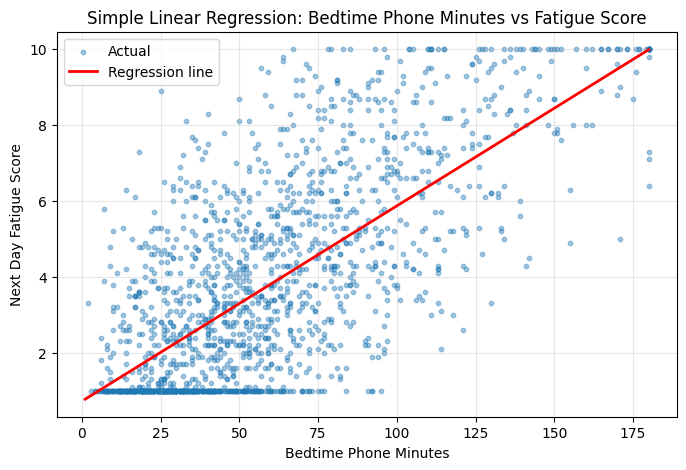

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(Xs_test, ys_test, alpha=0.4, s=10, label="Actual")
line_x = np.linspace(X_simple.min().iloc[0], X_simple.max().iloc[0], 100).reshape(-1, 1)
plt.plot(line_x, slr.predict(pd.DataFrame(line_x, columns=[main_independent])), color="red", linewidth=2, label="Regression line")
plt.title("Simple Linear Regression: Bedtime Phone Minutes vs Fatigue Score")
plt.xlabel("Bedtime Phone Minutes")
plt.ylabel("Next Day Fatigue Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Regression Equation (Simple Linear Regression)
Equation: **Fatigue = b0 + b1 × bedtime_phone_minutes**

In [31]:
b0 = slr.intercept_
b1 = slr.coef_[0]
print(f"Fatigue = {b0:.4f} + ({b1:.4f} × bedtime_phone_minutes)")

# Substitution examples
for minutes in [30, 90, 150]:
    manual = b0 + b1 * minutes
    model_pred = slr.predict(pd.DataFrame({main_independent: [minutes]}))[0]
    print(f"\n{minutes} minutes: Fatigue = {b0:.4f} + ({b1:.4f} × {minutes}) = {manual:.4f}")
    print(f"Model prediction = {model_pred:.4f}")

Fatigue = 0.7261 + (0.0515 × bedtime_phone_minutes)

30 minutes: Fatigue = 0.7261 + (0.0515 × 30) = 2.2698
Model prediction = 2.2698

90 minutes: Fatigue = 0.7261 + (0.0515 × 90) = 5.3573
Model prediction = 5.3573

150 minutes: Fatigue = 0.7261 + (0.0515 × 150) = 8.4448
Model prediction = 8.4448


### 6.2 Multiple Linear Regression
All relevant independent variables are used to predict **next_day_fatigue_score**.

In [32]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)

mlr_r2 = r2_score(y_test, y_pred_mlr)
mlr_mae = mean_absolute_error(y_test, y_pred_mlr)
mlr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_mlr))

print("R² score:", round(mlr_r2, 4))
print("MAE     :", round(mlr_mae, 4))
print("RMSE    :", round(mlr_rmse, 4))

R² score: 0.9157
MAE     : 0.623
RMSE    : 0.7925


In [33]:
coef_table = pd.DataFrame({"Variable": X_train.columns, "Coefficient": mlr.coef_.round(4)})
print("Intercept (b0):", round(mlr.intercept_, 4))
coef_table

Intercept (b0): 8.9002


,Variable,Coefficient
0,age,-0.0000
1,bedtime_phone_minutes,0.0072
2,screen_brightness_pct,0.0050
3,blue_light_filter_active,-0.1471
4,caffeine_post_5pm_mg,0.0039
5,physical_activity_min,0.0000
6,sleep_latency_min,0.0313
7,total_sleep_hours,-1.0378
8,deep_sleep_pct,-0.0641
9,rem_sleep_pct,-0.0010


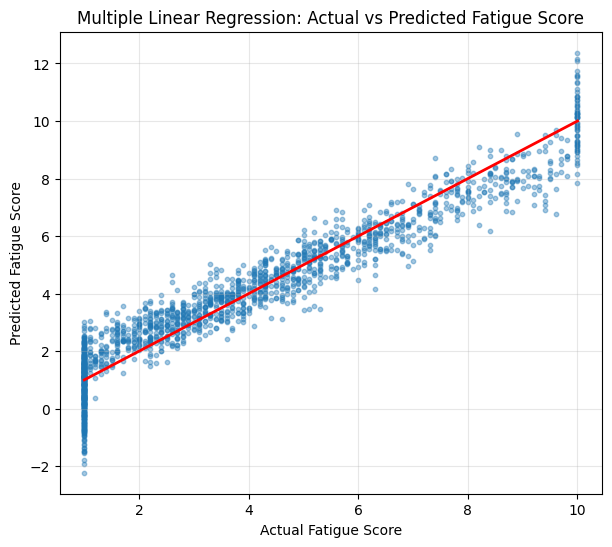

In [34]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_mlr, alpha=0.4, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linewidth=2)
plt.title("Multiple Linear Regression: Actual vs Predicted Fatigue Score")
plt.xlabel("Actual Fatigue Score")
plt.ylabel("Predicted Fatigue Score")
plt.grid(alpha=0.3)
plt.show()

#### Regression Equation (Multiple Linear Regression)
Equation: **Fatigue = b0 + b1·x1 + b2·x2 + ... + bn·xn**

In [35]:
equation = f"Fatigue = {mlr.intercept_:.4f}"
for name, coef in zip(X_train.columns, mlr.coef_):
    equation += f" + ({coef:.4f} × {name})"
print(equation)

Fatigue = 8.9002 + (-0.0000 × age) + (0.0072 × bedtime_phone_minutes) + (0.0050 × screen_brightness_pct) + (-0.1471 × blue_light_filter_active) + (0.0039 × caffeine_post_5pm_mg) + (0.0000 × physical_activity_min) + (0.0313 × sleep_latency_min) + (-1.0378 × total_sleep_hours) + (-0.0641 × deep_sleep_pct) + (-0.0010 × rem_sleep_pct) + (0.3863 × morning_alarm_snoozes) + (-0.2884 × sleep_debt_category) + (-0.0080 × gender_Male) + (-0.0224 × gender_Non-Binary) + (0.0230 × occupation_type_Freelance / Creative) + (0.2148 × occupation_type_Healthcare / Shift Worker) + (0.0144 × occupation_type_Remote Tech) + (0.0154 × occupation_type_Student) + (0.0680 × chronotype_Morning Lark) + (0.2086 × chronotype_Night Owl) + (0.0051 × primary_bedtime_app_Messaging / Chat) + (0.0546 × primary_bedtime_app_News / Reading) + (-0.0061 × primary_bedtime_app_Streaming (Netflix/Hulu)) + (0.0631 × primary_bedtime_app_TikTok / Reels) + (0.0450 × primary_bedtime_app_YouTube)


In [36]:
# Substitution example using the first record of the test set
sample_row = X_test.iloc[0]
manual_pred = mlr.intercept_ + np.sum(mlr.coef_ * sample_row.values)

substitution = pd.DataFrame({
    "Variable": X_train.columns,
    "Value (x)": sample_row.values,
    "Coefficient (b)": mlr.coef_.round(4),
    "b × x": (mlr.coef_ * sample_row.values).round(4)
})
print(substitution.to_string(index=False))

print("\nIntercept (b0):", round(mlr.intercept_, 4))
print("Manual calculation  :", round(manual_pred, 4))
print("Model prediction    :", round(mlr.predict(X_test.iloc[[0]])[0], 4))
print("Actual fatigue score:", y_test.iloc[0])

                                    Variable  Value (x)  Coefficient (b)   b × x
                                         age      42.00          -0.0000 -0.0018
                       bedtime_phone_minutes       7.00           0.0072  0.0502
                       screen_brightness_pct      53.00           0.0050  0.2664
                    blue_light_filter_active       1.00          -0.1471 -0.1471
                        caffeine_post_5pm_mg       0.00           0.0039  0.0000
                       physical_activity_min      38.00           0.0000  0.0004
                           sleep_latency_min      20.40           0.0313  0.6384
                           total_sleep_hours       8.59          -1.0378 -8.9145
                              deep_sleep_pct      21.30          -0.0641 -1.3656
                               rem_sleep_pct      22.00          -0.0010 -0.0216
                       morning_alarm_snoozes       0.00           0.3863  0.0000
                         sle

### 6.3 Comparison of Regression Models

In [37]:
regression_results = pd.DataFrame({
    "Model": ["Simple Linear Regression", "Multiple Linear Regression"],
    "R²": [slr_r2, mlr_r2],
    "MAE": [slr_mae, mlr_mae],
    "RMSE": [slr_rmse, mlr_rmse]
}).round(4)
regression_results

,Model,R²,MAE,RMSE
0,Simple Linear Regression,0.5159,1.5117,1.8995
1,Multiple Linear Regression,0.9157,0.6230,0.7925


---
## 7. Classification Models

### 7.1 Target Variable Categorization
The fatigue score (1–10) is converted into two classes using the midpoint of the scale:
- **0 = Low Fatigue** → score < 5
- **1 = High Fatigue** → score ≥ 5

In [38]:
y_class = (df_encoded[dependent_var] >= 5).astype(int)
X_class = df_encoded.drop(columns=[dependent_var])

class_names = ["Low Fatigue", "High Fatigue"]
print(y_class.map({0: "Low Fatigue", 1: "High Fatigue"}).value_counts())

next_day_fatigue_score
Low Fatigue     5904
High Fatigue    2596
Name: count, dtype: int64


### 7.2 Class Distribution Analysis

          Class  Count  Percentage (%)
0   Low Fatigue   5904           69.46
1  High Fatigue   2596           30.54


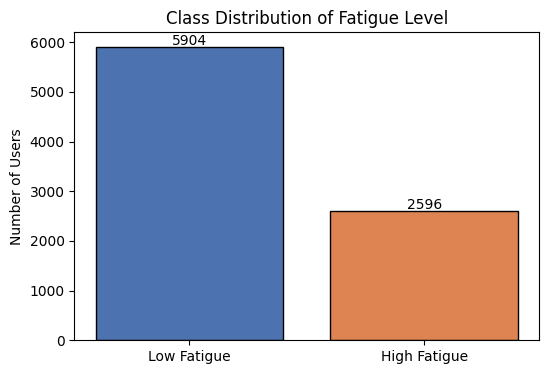

In [39]:
class_counts = y_class.value_counts().sort_index()
class_pct = (y_class.value_counts(normalize=True).sort_index() * 100).round(2)
print(pd.DataFrame({"Class": class_names, "Count": class_counts.values, "Percentage (%)": class_pct.values}))

plt.figure(figsize=(6, 4))
plt.bar(class_names, class_counts.values, color=["#4C72B0", "#DD8452"], edgecolor="black")
for i, v in enumerate(class_counts.values):
    plt.text(i, v + 50, str(v), ha="center")
plt.title("Class Distribution of Fatigue Level")
plt.ylabel("Number of Users")
plt.show()

In [40]:
# Split (stratify keeps the same class ratio in training and testing data)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_class, y_class, test_size=0.2,
                                                        random_state=42, stratify=y_class)

print("Training class counts:", yc_train.value_counts().sort_index().tolist())
print("Testing class counts :", yc_test.value_counts().sort_index().tolist())

# Feature scaling for classification
scaler_c = StandardScaler()
Xc_train_scaled = scaler_c.fit_transform(Xc_train)
Xc_test_scaled = scaler_c.transform(Xc_test)

Training class counts: [4723, 2077]
Testing class counts : [1181, 519]


### 7.3 Building the Classifiers
Each model is evaluated with the **confusion matrix** and **accuracy**.

In [41]:
def evaluate_classifier(name, model, Xtr, Xte):
    model.fit(Xtr, yc_train)
    pred = model.predict(Xte)
    acc = accuracy_score(yc_test, pred)
    cm = confusion_matrix(yc_test, pred)

    print(name)
    print("Accuracy:", round(acc, 4))
    print("Confusion Matrix:")
    print(cm)
    print(classification_report(yc_test, pred, target_names=class_names))

    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
    plt.title("Confusion Matrix - " + name)
    plt.show()
    return acc

#### Logistic Regression

Logistic Regression
Accuracy: 0.9494
Confusion Matrix:
[[1142   39]
 [  47  472]]
              precision    recall  f1-score   support

 Low Fatigue       0.96      0.97      0.96      1181
High Fatigue       0.92      0.91      0.92       519

    accuracy                           0.95      1700
   macro avg       0.94      0.94      0.94      1700
weighted avg       0.95      0.95      0.95      1700



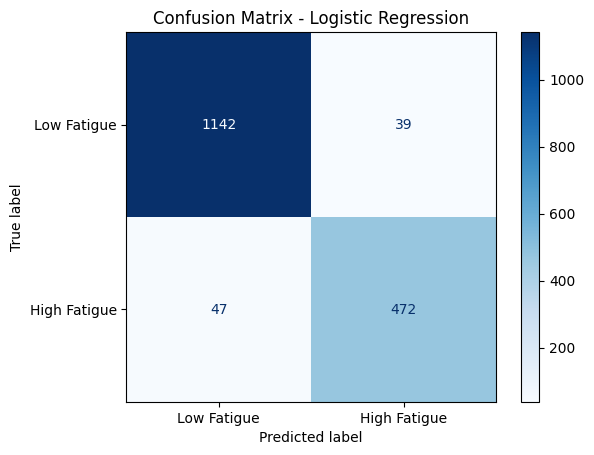

In [42]:
log_model = LogisticRegression(max_iter=1000, random_state=42)
acc_log = evaluate_classifier("Logistic Regression", log_model, Xc_train_scaled, Xc_test_scaled)

#### K-Nearest Neighbors (KNN)
The best value of k is selected by testing k = 1 to 20.

c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\Zain Faisal\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 966, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Zain Faisal\AppData\Local\Prog

Best k: 19 | Accuracy: 0.9106


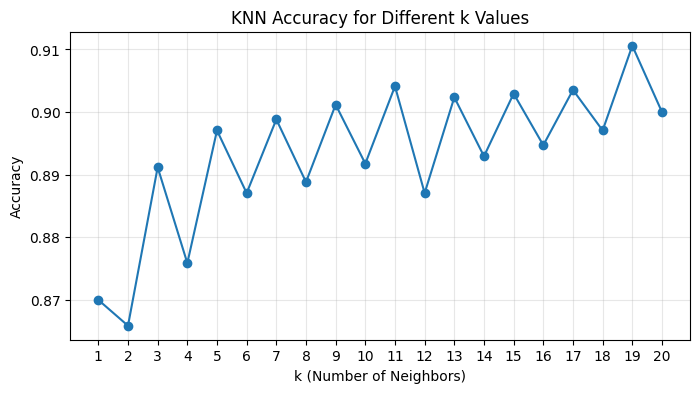

In [43]:
k_values = range(1, 21)
k_scores = []
for kk in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=kk)
    knn_temp.fit(Xc_train_scaled, yc_train)
    k_scores.append(accuracy_score(yc_test, knn_temp.predict(Xc_test_scaled)))

best_k = list(k_values)[int(np.argmax(k_scores))]
print("Best k:", best_k, "| Accuracy:", round(max(k_scores), 4))

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), k_scores, marker="o")
plt.title("KNN Accuracy for Different k Values")
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

KNN (k=19)
Accuracy: 0.9106
Confusion Matrix:
[[1151   30]
 [ 122  397]]
              precision    recall  f1-score   support

 Low Fatigue       0.90      0.97      0.94      1181
High Fatigue       0.93      0.76      0.84       519

    accuracy                           0.91      1700
   macro avg       0.92      0.87      0.89      1700
weighted avg       0.91      0.91      0.91      1700



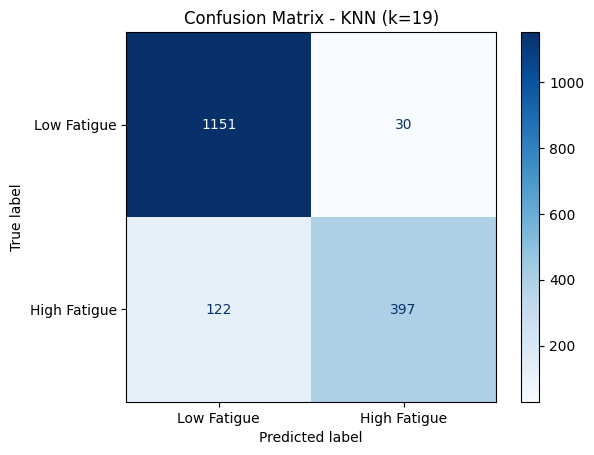

In [44]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
acc_knn = evaluate_classifier(f"KNN (k={best_k})", knn_model, Xc_train_scaled, Xc_test_scaled)

#### Naïve Bayes

Naive Bayes
Accuracy: 0.9159
Confusion Matrix:
[[1061  120]
 [  23  496]]
              precision    recall  f1-score   support

 Low Fatigue       0.98      0.90      0.94      1181
High Fatigue       0.81      0.96      0.87       519

    accuracy                           0.92      1700
   macro avg       0.89      0.93      0.91      1700
weighted avg       0.93      0.92      0.92      1700



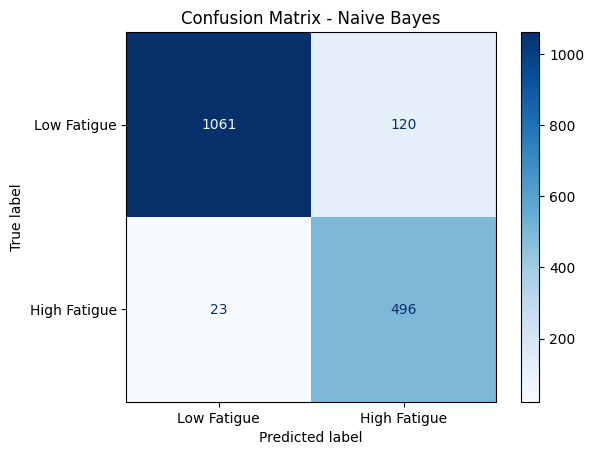

In [45]:
nb_model = GaussianNB()
acc_nb = evaluate_classifier("Naive Bayes", nb_model, Xc_train_scaled, Xc_test_scaled)

#### Decision Tree
The best max_depth is selected by testing depths 1 to 15.

In [46]:
depths = range(1, 16)
depth_scores = []
for dpt in depths:
    dt_temp = DecisionTreeClassifier(max_depth=dpt, random_state=42)
    dt_temp.fit(Xc_train, yc_train)
    depth_scores.append(accuracy_score(yc_test, dt_temp.predict(Xc_test)))

best_depth = list(depths)[int(np.argmax(depth_scores))]
print("Best max_depth:", best_depth, "| Accuracy:", round(max(depth_scores), 4))

Best max_depth: 5 | Accuracy: 0.9294


Decision Tree (max_depth=5)
Accuracy: 0.9294
Confusion Matrix:
[[1118   63]
 [  57  462]]
              precision    recall  f1-score   support

 Low Fatigue       0.95      0.95      0.95      1181
High Fatigue       0.88      0.89      0.89       519

    accuracy                           0.93      1700
   macro avg       0.92      0.92      0.92      1700
weighted avg       0.93      0.93      0.93      1700



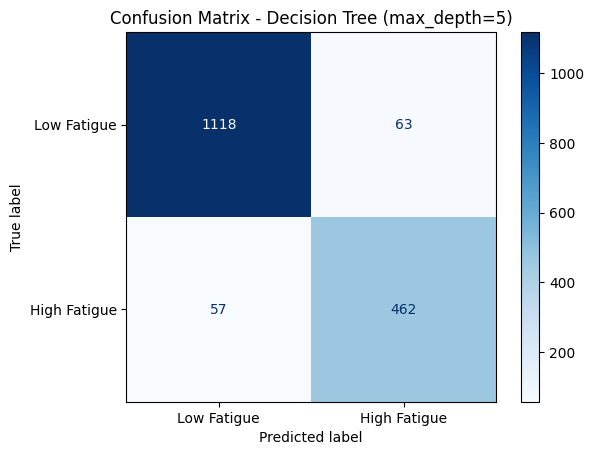

In [47]:
dt_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
acc_dt = evaluate_classifier(f"Decision Tree (max_depth={best_depth})", dt_model, Xc_train, Xc_test)

### 7.4 Comparison of Classifiers and Best-Fit Model

                     Model  Accuracy
0      Logistic Regression    0.9494
1  Decision Tree (depth=5)    0.9294
2              Naive Bayes    0.9159
3               KNN (k=19)    0.9106


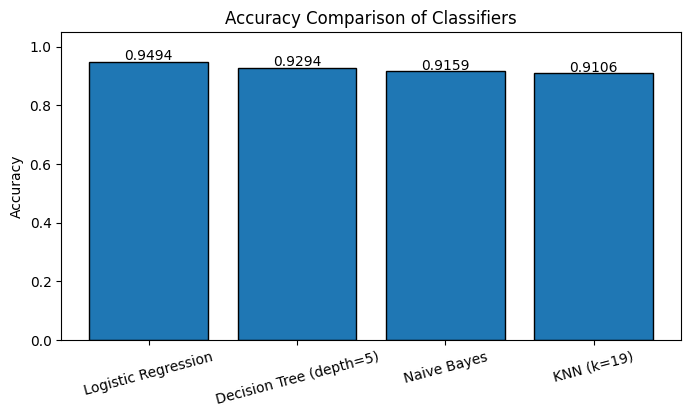

Best-fit classifier: Logistic Regression


In [48]:
classifier_results = pd.DataFrame({
    "Model": ["Logistic Regression", f"KNN (k={best_k})", "Naive Bayes", f"Decision Tree (depth={best_depth})"],
    "Accuracy": [acc_log, acc_knn, acc_nb, acc_dt]
}).round(4).sort_values("Accuracy", ascending=False).reset_index(drop=True)
print(classifier_results)

plt.figure(figsize=(8, 4))
plt.bar(classifier_results["Model"], classifier_results["Accuracy"], edgecolor="black")
for i, v in enumerate(classifier_results["Accuracy"]):
    plt.text(i, v + 0.005, f"{v:.4f}", ha="center")
plt.title("Accuracy Comparison of Classifiers")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.show()

best_model_name = classifier_results.loc[0, "Model"]
print("Best-fit classifier:", best_model_name)

### 7.5 Prediction using the Best-Fit Classifier

In [49]:
models = {"Logistic Regression": (log_model, True), f"KNN (k={best_k})": (knn_model, True),
          "Naive Bayes": (nb_model, True), f"Decision Tree (depth={best_depth})": (dt_model, False)}
best_model, needs_scaling = models[best_model_name]

def predict_fatigue(raw_records):
    data = encode_features(raw_records)
    data = data.reindex(columns=X_class.columns, fill_value=0)
    if needs_scaling:
        data = scaler_c.transform(data)
    return best_model.predict(data)

# Predict for the first 10 users of the test set
test_preds = predict_fatigue(df_model.loc[Xc_test.index[:10]].drop(columns=[dependent_var]))
pred_table = pd.DataFrame({
    "Actual Score": df_model.loc[Xc_test.index[:10], dependent_var].values,
    "Actual Class": [class_names[c] for c in yc_test.iloc[:10]],
    "Predicted Class": [class_names[c] for c in test_preds]
})
pred_table

,Actual Score,Actual Class,Predicted Class
0,1.0,Low Fatigue,Low Fatigue
1,1.7,Low Fatigue,Low Fatigue
2,4.3,Low Fatigue,Low Fatigue
3,4.6,Low Fatigue,Low Fatigue
4,4.3,Low Fatigue,Low Fatigue
5,10.0,High Fatigue,High Fatigue
6,1.5,Low Fatigue,Low Fatigue
7,4.1,Low Fatigue,Low Fatigue
8,1.0,Low Fatigue,Low Fatigue
9,6.0,High Fatigue,Low Fatigue


In [50]:
# Predict for new users
new_users = pd.DataFrame([
    {"age": 22, "gender": "Female", "occupation_type": "Student",
     "chronotype": "Night Owl", "bedtime_phone_minutes": 150,
     "primary_bedtime_app": "TikTok / Reels", "screen_brightness_pct": 80,
     "blue_light_filter_active": 0, "caffeine_post_5pm_mg": 120, "physical_activity_min": 10,
     "sleep_latency_min": 75.0, "total_sleep_hours": 4.0, "deep_sleep_pct": 16.0, "rem_sleep_pct": 19.0,
     "morning_alarm_snoozes": 6, "sleep_debt_category": "Severe Sleep Debt"},
    {"age": 35, "gender": "Male", "occupation_type": "Remote Tech",
     "chronotype": "Intermediate", "bedtime_phone_minutes": 15,
     "primary_bedtime_app": "YouTube", "screen_brightness_pct": 30,
     "blue_light_filter_active": 1, "caffeine_post_5pm_mg": 0, "physical_activity_min": 60,
     "sleep_latency_min": 12.0, "total_sleep_hours": 8.0, "deep_sleep_pct": 24.0, "rem_sleep_pct": 23.0,
     "morning_alarm_snoozes": 0, "sleep_debt_category": "Optimal Recovery"}
])

new_preds = predict_fatigue(new_users)
for i, p in enumerate(new_preds):
    print(f"New user {i + 1}: phone = {new_users.loc[i, 'bedtime_phone_minutes']} min, "
          f"sleep = {new_users.loc[i, 'total_sleep_hours']} h  ->  Predicted: {class_names[p]}")

New user 1: phone = 150 min, sleep = 4.0 h  ->  Predicted: High Fatigue
New user 2: phone = 15 min, sleep = 8.0 h  ->  Predicted: Low Fatigue


---
## 8. Cluster Analysis
Fields used: **bedtime_phone_minutes** and **next_day_fatigue_score**. The fields are scaled before clustering because they have different units.

In [51]:
cluster_features = ["bedtime_phone_minutes", dependent_var]
X_cluster = df_model[cluster_features]

cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)
print("Clustering data shape:", X_cluster_scaled.shape)

Clustering data shape: (8500, 2)


### 8.1 K-Means Clustering
#### Finding the optimal number of clusters (Elbow Method and Silhouette Score)

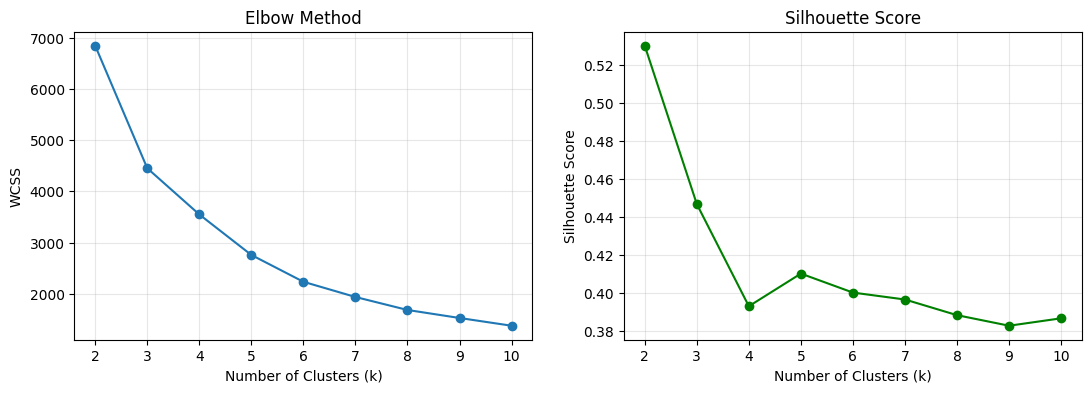

 k    WCSS  Silhouette
 2 6842.34      0.5302
 3 4451.29      0.4469
 4 3549.14      0.3932
 5 2758.51      0.4103
 6 2234.96      0.4004
 7 1938.10      0.3967
 8 1684.56      0.3885
 9 1528.19      0.3829
10 1377.14      0.3868


In [52]:
wcss = []
sil_scores = []
k_range = range(2, 11)
for kc in k_range:
    km = KMeans(n_clusters=kc, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(list(k_range), wcss, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of Clusters (k)")
ax[0].set_ylabel("WCSS")
ax[0].grid(alpha=0.3)
ax[1].plot(list(k_range), sil_scores, marker="o", color="green")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of Clusters (k)")
ax[1].set_ylabel("Silhouette Score")
ax[1].grid(alpha=0.3)
plt.show()

print(pd.DataFrame({"k": list(k_range), "WCSS": np.round(wcss, 2), "Silhouette": np.round(sil_scores, 4)}).to_string(index=False))

Silhouette score (k = 3 ): 0.4469


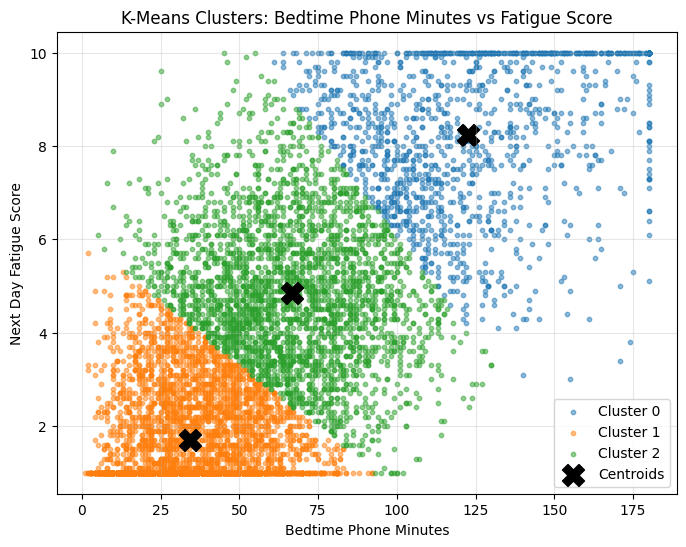

In [53]:
optimal_k = 3       # selected from the elbow point and silhouette score above (change if your elbow is different)
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_model["kmeans_cluster"] = kmeans.fit_predict(X_cluster_scaled)

print("Silhouette score (k =", optimal_k, "):", round(silhouette_score(X_cluster_scaled, df_model["kmeans_cluster"]), 4))

centers = cluster_scaler.inverse_transform(kmeans.cluster_centers_)
plt.figure(figsize=(8, 6))
for c in range(optimal_k):
    part = df_model[df_model["kmeans_cluster"] == c]
    plt.scatter(part["bedtime_phone_minutes"], part[dependent_var], s=10, alpha=0.5, label=f"Cluster {c}")
plt.scatter(centers[:, 0], centers[:, 1], s=250, c="black", marker="X", label="Centroids")
plt.title("K-Means Clusters: Bedtime Phone Minutes vs Fatigue Score")
plt.xlabel("Bedtime Phone Minutes")
plt.ylabel("Next Day Fatigue Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [54]:
# Profile of each K-Means cluster
profile_cols = ["bedtime_phone_minutes", dependent_var, "total_sleep_hours", "sleep_latency_min",
                "screen_brightness_pct", "caffeine_post_5pm_mg", "physical_activity_min", "morning_alarm_snoozes"]
kmeans_profile = df_model.groupby("kmeans_cluster")[profile_cols].mean().round(2)
kmeans_profile.insert(0, "Users", df_model["kmeans_cluster"].value_counts().sort_index())
kmeans_profile

,Users,bedtime_phone_minutes,next_day_fatigue_score,total_sleep_hours,sleep_latency_min,screen_brightness_pct,caffeine_post_5pm_mg,physical_activity_min,morning_alarm_snoozes
kmeans_cluster,,,,,,,,,
0,1317,122.49,8.22,4.44,68.56,57.28,38.73,34.84,5.15
1,4257,34.48,1.69,7.26,29.47,54.48,27.29,35.98,1.58
2,2926,66.82,4.86,5.64,44.42,55.17,39.37,35.68,3.42


### 8.2 Hierarchical Clustering
A random sample of 1,000 users is used for the dendrogram so that it is readable.

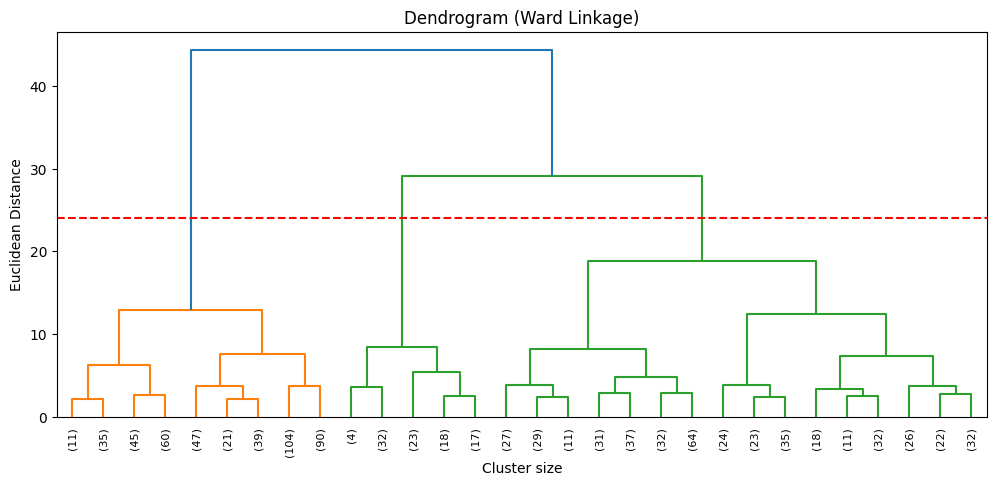

In [55]:
hc_sample_idx = np.random.RandomState(42).choice(len(X_cluster_scaled), 1000, replace=False)
linked = linkage(X_cluster_scaled[hc_sample_idx], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linked, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8)
cut_height = (linked[-optimal_k, 2] + linked[-optimal_k + 1, 2]) / 2          # cut line for the chosen clusters
plt.axhline(y=cut_height, color="red", linestyle="--")
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Cluster size")
plt.ylabel("Euclidean Distance")
plt.show()

Silhouette score (Hierarchical, k = 3 ): 0.3479


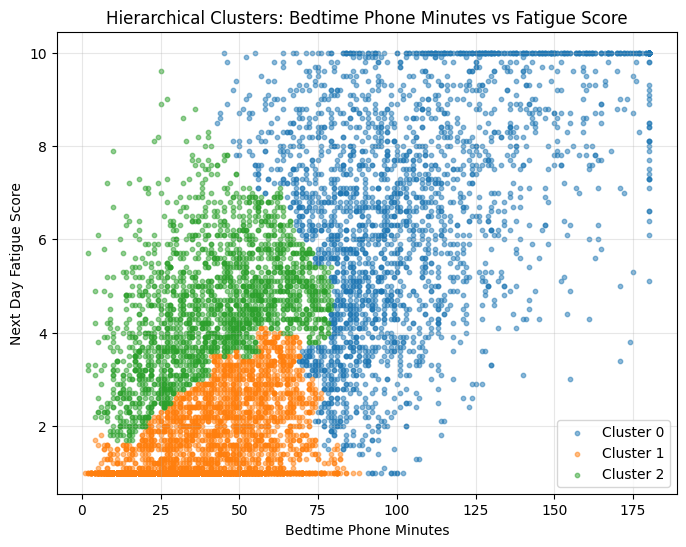

In [56]:
hc = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
df_model["hc_cluster"] = hc.fit_predict(X_cluster_scaled)

print("Silhouette score (Hierarchical, k =", optimal_k, "):", round(silhouette_score(X_cluster_scaled, df_model["hc_cluster"]), 4))

plt.figure(figsize=(8, 6))
for c in range(optimal_k):
    part = df_model[df_model["hc_cluster"] == c]
    plt.scatter(part["bedtime_phone_minutes"], part[dependent_var], s=10, alpha=0.5, label=f"Cluster {c}")
plt.title("Hierarchical Clusters: Bedtime Phone Minutes vs Fatigue Score")
plt.xlabel("Bedtime Phone Minutes")
plt.ylabel("Next Day Fatigue Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [57]:
# Profile of each Hierarchical cluster
hc_profile = df_model.groupby("hc_cluster")[profile_cols].mean().round(2)
hc_profile.insert(0, "Users", df_model["hc_cluster"].value_counts().sort_index())
hc_profile

,Users,bedtime_phone_minutes,next_day_fatigue_score,total_sleep_hours,sleep_latency_min,screen_brightness_pct,caffeine_post_5pm_mg,physical_activity_min,morning_alarm_snoozes
hc_cluster,,,,,,,,,
0,2561,104.22,6.62,5.08,59.57,55.64,36.05,35.29,4.34
1,3910,38.64,1.55,7.40,30.53,54.26,23.95,36.27,1.49
2,2029,42.20,4.55,5.59,36.36,56.27,47.51,35.13,3.24


In [58]:
# Sleep debt category in each K-Means cluster
pd.crosstab(df_model["kmeans_cluster"], df_model["sleep_debt_category"])

sleep_debt_category,Mild Deficit,Moderate Debt,Optimal Recovery,Severe Sleep Debt
kmeans_cluster,,,,
0,15,692,0,610
1,1629,1272,1356,0
2,360,2498,31,37
